# [경기도 팜맵으로 농경지 면적 구하기]

In [3]:
import geopandas as gpd
import pandas as pd
import glob
import os

### 00. 팜맵 데이터 준비

- 시군단위로 나뉘어진 데이터를 병합하여 gpkg로 저장한다.

In [3]:
def merge(path, name):
    # 하위 폴더에 있는 모든 shp 검색(리스트로 저장됨)
    shp_files = glob.glob(os.path.join(path, '*', '*.shp'))

    # shp 파일 전부를 gdf_list에 저장
    gdf_list = []

    for shp in shp_files:
        gdf = gpd.read_file(shp, encoding='CP949')
        
        if gdf.crs != 'EPSG:5179':
            gdf = gdf.to_crs('EPSG:5179') # 원본 각 지역의 좌표계가 EPSG:5179로 통일되어있지 않아서 5179로 통일
        else:
            gdf = gdf

        gdf_list.append(gdf)

    # gdf_list에 있는 모든 gdf를 merge
    gdf_merge = gpd.GeoDataFrame(
        pd.concat(gdf_list, ignore_index=True), # ignore_index=True : 인덱스를 새로 부여
        crs='EPSG:5179' # 좌표계 통일
    )

    # gpkg로 저장
    gdf_merge.to_file(os.path.join(path, name), driver='GPKG', encoding='CP949')

path = r'C:\WORK\00. project\project_01\data\farmmap_geonggi_20251231'
name = 'farm_gg_2025.gpkg'

merge(path, name)

- 저장한 gpkg를 불러와서 변수에 저장 후 필요한 컬럼만 남김.

In [4]:
farm_gg_2025 = gpd.read_file(r'C:\WORK\00. project\project_01\data'
                             r'\farmmap_geonggi_20251231\farm_gg_2025.gpkg', encoding='cp949')


# 팜맵 홈페이지에 제공된 정보에 해당하는 컬럼만 남기고 다시 변수에 저장한다.

major_columns = ['ID',          # 주소기반 ID / 단일키
                'CLSF_CD',      # 분류코드(01:논 02:밭 03:과수 04:시설 06:비경지)
                'STDG_CD',      # 법정동코드 10자리
                'STDG_ADDR',    # 법정동주소
                'PNU',          # 가장 중첩면적이 큰 지적필지의 PNU 입력
                'LDCG_CD',      # 가장 중첩면적이 큰 지적필지의 지목코드값을 입력
                'AREA',         # 농경지 구획 면적
                'CAD_CON_RA',   # 지적일치율
                'FLIGHT_YMD',   # 영상촬영일자
                'UPDT_YMD',     # 갱신일자
                'geometry'      # 폴리곤 좌표
                ]

farm_gg_2025 = farm_gg_2025[major_columns]

- 팜맵 데이터 전처리

In [5]:
def columns_add(path, gdf):
    gdf['YN_MNT'] = (gdf['PNU'].str[10].replace({'0':'', '1': '', '2': ' 산'}))
    gdf['LN_MN'] = (gdf['PNU'].str[11:15].str.lstrip('0').fillna(''))
    gdf['LN_SN'] = (gdf['PNU'].str[15:19].str.lstrip('0').fillna(''))
    gdf['LN_ADDR'] = (gdf['STDG_ADDR'] + gdf['YN_MNT'] + gdf['LN_MN'] + 
                ('-' + gdf['LN_SN']).where((gdf['LN_MN'] != '') & (gdf['LN_SN'] != ''), gdf['LN_SN']))

    # 법정동코드(STDG_CD)로 시도(SIDO_CD), 시군구(SGG_CD), 읍면동(EMD_CD), 리(LI_CD) 컬럼을 만들어 각각 입력
    gdf['SIDO_CD'] = gdf['STDG_CD'].str[:2]
    gdf['SGG_CD'] = gdf['STDG_CD'].str[2:5]
    gdf['EMD_CD'] = gdf['STDG_CD'].str[5:8]
    gdf['LI_CD'] = gdf['STDG_CD'].str[8:]

    # 국토교통부에서 제공하는 전국 법정동코드 csv를 불러와서 팜맵 데이터와 조인
    bemd_cd = pd.read_csv('BEMD_CD.csv')
    bemd_cd['법정동코드'] = bemd_cd['법정동코드'].astype(str)

    gdf = gdf.merge(bemd_cd, left_on='STDG_CD', right_on='법정동코드', how='left')

    # 한글로 된 컬럼 이름을 영어로 변경
    gdf = gdf.rename(columns={'시도명':'SIDO_NM', '시군구명':'SGG_NM', '읍면동명':'EMD_NM', '리명':'LI_NM'})

    # 필요한 컬럼만 남기고 다시 저장
    gdf = gdf[['ID', 'CLSF_CD', 'STDG_CD', 'STDG_ADDR', 'PNU', 'LDCG_CD', 'AREA', 'CAD_CON_RA', 
                             'FLIGHT_YMD', 'UPDT_YMD', 'SIDO_CD', 'SGG_CD', 'EMD_CD', 'LI_CD', 
                             'SIDO_NM', 'SGG_NM', 'EMD_NM', 'LI_NM', 'geometry']]

    # 결과를 새로운 gpkg로 저장
    return gdf.to_file(os.path.join(path, 'farm_gg_2025_new.gpkg'), driver='gpkg', encoding='cp949', overwrite=True)

path = r'C:\WORK\00. project\project_01\data\farmmap_geonggi_20251231'

columns_add(path ,farm_gg_2025)

In [95]:
farm_gg_2025_new = gpd.read_file(os.path.join(path, 'farm_gg_2025_new.gpkg'), encoding='cp949')
farm_gg_2025_new

,ID,CLSF_CD,STDG_CD,STDG_ADDR,PNU,LDCG_CD,AREA,CAD_CON_RA,FLIGHT_YMD,UPDT_YMD,SIDO_CD,SGG_CD,EMD_CD,LI_CD,SIDO_NM,SGG_NM,EMD_NM,LI_NM,geometry
0,418003202500471,02,4180032025,경기도 연천군 청산면 백의리,4180032025200760001,임,428.873500,98.89,2022-12-30,2023-12-28,41,800,320,25,경기도,연천군,청산면,백의리,"POLYGON ((968245.638 2002457.047, 968246.3 200..."
1,418003202500619,02,4180032025,경기도 연천군 청산면 백의리,4180032025200590002,임,169.411267,75.81,2022-12-30,2023-12-28,41,800,320,25,경기도,연천군,청산면,백의리,"POLYGON ((968206.228 2002344.084, 968220.027 2..."
2,418003202500212,04,4180032025,경기도 연천군 청산면 백의리,4180032025200300007,임,997.509702,60.54,2022-12-30,2023-12-28,41,800,320,25,경기도,연천군,청산면,백의리,"POLYGON ((966920.098 2002893.74, 966924.216 20..."
3,418003202500228,02,4180032025,경기도 연천군 청산면 백의리,4180032025200260012,임,299.921901,70.02,2022-12-30,2023-12-28,41,800,320,25,경기도,연천군,청산면,백의리,"POLYGON ((966872.316 2002811.84, 966873.109 20..."
4,418003202500078,02,4180032025,경기도 연천군 청산면 백의리,4180032025200260001,임,1008.111296,99.64,2022-12-30,2023-12-28,41,800,320,25,경기도,연천군,청산면,백의리,"POLYGON ((966983.581 2003976.69, 966979.527 20..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1186441,415913302800008,01,4159133028,경기도 화성시 만세구 서신면 매화리,4159133028105500010,답,2929.170000,91.23,2024-12-31,2025-12-31,41,591,330,28,경기도,화성시만세구,서신면,매화리,"POLYGON ((929048.837 1907195.234, 929050.401 1..."
1186442,415903502900746,02,4159133028,경기도 화성시 만세구 서신면 매화리,4159133028105500001,답,1188.531141,97.91,2020-09-01,None,41,591,330,28,경기도,화성시만세구,서신면,매화리,"POLYGON ((929002.858 1907176.753, 928995.67 19..."
1186443,415913203200026,01,4159132032,경기도 화성시 만세구 송산면 지화리,4159132032105050014,답,2094.810000,47.97,2024-12-31,2025-12-31,41,591,320,32,경기도,화성시만세구,송산면,지화리,"POLYGON ((926297.815 1912535.676, 926297.814 1..."
1186444,415903202401892,06,4159332024,경기도 화성시 효행구 비봉면 삼화리,4159332024105970000,전,4.102717,100.00,2023-12-30,2024-12-31,41,593,320,24,경기도,화성시효행구,비봉면,삼화리,"POLYGON ((943188.036 1915735.355, 943189.53 19..."


### 01. 형상 및 속성정보 검수

- 속성정보 검수
    - PK가 중복된 데이터

- 지오메트리 검수
    - 지오메트리가 유효하지 않은 데이터
    - 지오메트리가 Null인 데이터
    - 지오메트리가 비어있는 데이터
    - 지오메트리의 면적이 0인 데이터

In [96]:
def check_farm(gdf, path):

    duplicated_pk = gdf[gdf['ID'].duplicated()]
    invalid_data = gdf[~gdf.geometry.is_valid].copy()
    null_data = gdf[gdf.geometry.isna()].copy()
    empty_data = gdf[gdf.geometry.is_empty].copy()
    Zero_area = gdf[gdf.geometry.area == 0].copy()

    print(f'1. 전체 데이터 수: {len(gdf):,}')

    print(f'2. PK가 중복된 데이터 수: {len(duplicated_pk):,}')
    if len(duplicated_pk) > 0:
        print(f'2.1. PK 중복 데이터 확인: \n{duplicated_pk}')
        # PK 중복 데이터 gpkg로 export
        duplicated_pk.to_file(os.path.join(path, 'Duplicated_data.gpkg'),
                                driver='GPKG', encoding='cp949', overwrite=True)

    print(f'3. 유효하지 않은 데이터 갯수: {len(invalid_data):,}')
    if len(invalid_data) > 0:
        print(f'3.1. 유효하지 않은 데이터 확인: \n{invalid_data.is_valid_reason()}')

        # 유효하지 않은 데이터 리포트 export        
        invalid_data.is_valid_reason().to_excel(os.path.join(path, 'invalid_data.xlsx'))

        # 유효하지 않은 데이터 gpkg로 export
        invalid_data.to_file(os.path.join(path, 'Invalid_geometry.gpkg'), 
                             driver='GPKG', encoding='cp949', overwrite=True)

        # 유효하지 않은 데이터 수정
        invalid_data['geometry'] = (invalid_data.geometry.make_valid())
        gdf.loc[invalid_data.index, 'geometry'] = (invalid_data.geometry)


    print(f'4. Null 데이터 수: {len(null_data):,}')
    if len(null_data) > 0:
        print(f'4.1. Null 데이터 확인: \n{null_data}')
        # Null 데이터 gpkg로 export
        null_data.to_file(os.path.join(path, 'Null_geometry.gpkg'), 
                          driver='GPKG', encoding='cp949', overwrite=True)

    print(f'5. 빈 데이터 수: {len(empty_data):,}')
    if len(empty_data) > 0:
        print(f'5.1. 빈 데이터 확인: \n{empty_data}')
        # 빈 데이터 gpkg로 export
        empty_data.to_file(os.path.join(path, 'Empty_geometry.gpkg'), 
                           driver='GPKG', encoding='cp949', overwrite=True)

    print(f'6. 면적이 0인 데이터 수: {len(Zero_area):,}')
    if len(Zero_area) > 0:
        print(f'6.1. 면적이 0인 데이터 확인: \n{Zero_area}')
        # 면적이 0인 데이터 gpkg로 export
        Zero_area.to_file(os.path.join(path, 'Zero_area.gpkg'), 
                          driver='GPKG', encoding='cp949', overwrite=True)
    
anaylize_path = r'C:\WORK\00. project\project_01\data\farmmap_geonggi_20251231'

check_farm(farm_gg_2025_new, anaylize_path)

1. 전체 데이터 수: 1,186,446
2. PK가 중복된 데이터 수: 0
3. 유효하지 않은 데이터 갯수: 26
3.1. 유효하지 않은 데이터 확인: 
37358     Ring Self-intersection[956912.912499999 200582...
37359      Ring Self-intersection[957531.5715 2001819.4101]
37360     Ring Self-intersection[963663.773600001 201357...
95334     Ring Self-intersection[929140.306900001 198496...
95335      Ring Self-intersection[929263.7727 1979888.5789]
95336     Ring Self-intersection[937526.622700001 197573...
95337     Ring Self-intersection[940197.872299999 197758...
95338     Ring Self-intersection[938712.039499999 197696...
95339     Ring Self-intersection[945215.549899999 198442...
95340     Ring Self-intersection[940845.634899999 198362...
95341      Ring Self-intersection[929349.3743 1969137.1149]
297514     Ring Self-intersection[957404.6938 1990549.0612]
297610     Ring Self-intersection[959900.3585 1989131.7544]
320367     Ring Self-intersection[949906.5691 1919187.7026]
328459     Ring Self-intersection[933217.5309 1929883.0489]
332754     Ri

### 02. 경기도 지역별 농경지 면적 분석

- 경기도의 지역별 농경지 면적 분석
    - 시도, 시군구, 읍면동리 단위 면적 합산 결과를 csv로 export

In [ ]:
def area_calc(gdf):

    # 시도별 면적
    sido_area = (
        gdf
        .groupby(
            ['SIDO_CD', 'SIDO_NM'],
            dropna=False
        )
        .agg(면적_ha=('AREA', lambda x: x.sum() / 10_000))
        .reset_index()
    )

    # 시군구별 면적
    sgg_area = (
        gdf
        .groupby(
            ['SIDO_CD', 'SGG_CD', 'SIDO_NM', 'SGG_NM'],
            dropna=False
        )
        .agg(면적_ha=('AREA', lambda x: x.sum() / 10_000))
        .reset_index()
        .sort_values('SGG_NM', ascending=True)
    )

    # 읍면동리별 면적
    emdli_area = (
        gdf
        .groupby(
            [
                'SIDO_CD', 'SGG_CD', 'EMD_CD', 'LI_CD',
                'SIDO_NM', 'SGG_NM', 'EMD_NM', 'LI_NM'
            ],
            dropna=False
        )
        .agg(면적_ha=('AREA', lambda x: x.sum() / 10_000))
        .reset_index()
        .sort_values(['SGG_NM', 'EMD_NM', 'LI_NM'], ascending=True)
    )

    # CSV 저장
    sido_area.to_csv(
        '행정구역별면적_시도.csv',
        index=False,
        encoding='utf-8-sig'
    )

    sgg_area.to_csv(
        '행정구역별면적_시군구.csv',
        index=False,
        encoding='utf-8-sig'
    )

    emdli_area.to_csv(
        '행정구역별면적_읍면동리.csv',
        index=False,
        encoding='utf-8-sig'
    )

    display(sido_area.head())
    display(sgg_area.head())
    display(emdli_area.head())


area_calc(farm_gg_2025_new)

,SIDO_CD,SIDO_NM,면적_ha
0,41,경기도,156158.638250
1,41,NaN,2.559314


,SIDO_CD,SGG_CD,SIDO_NM,SGG_NM,면적_ha
46,41,820,경기도,가평군,3126.520319
18,41,281,경기도,고양시덕양구,1941.417386
19,41,285,경기도,고양시일산동구,809.156212
20,41,287,경기도,고양시일산서구,1101.883213
21,41,290,경기도,과천시,194.321422


,SIDO_CD,SGG_CD,EMD_CD,LI_CD,SIDO_NM,SGG_NM,EMD_NM,LI_NM,면적_ha
1795,41,820,250,30,경기도,가평군,가평읍,개곡리,79.382143
1792,41,820,250,27,경기도,가평군,가평읍,경반리,54.785395
1799,41,820,250,34,경기도,가평군,가평읍,금대리,35.441446
1788,41,820,250,23,경기도,가평군,가평읍,달전리,35.013609
1787,41,820,250,22,경기도,가평군,가평읍,대곡리,24.842215


- csv를 확인해보니 동코드에 잘못된 값이 들어간 경우가 있었다.
- 4159710400은 '경기도 화성시동탄구 오산동'으로 현재는 폐지된 행정구역이었다.
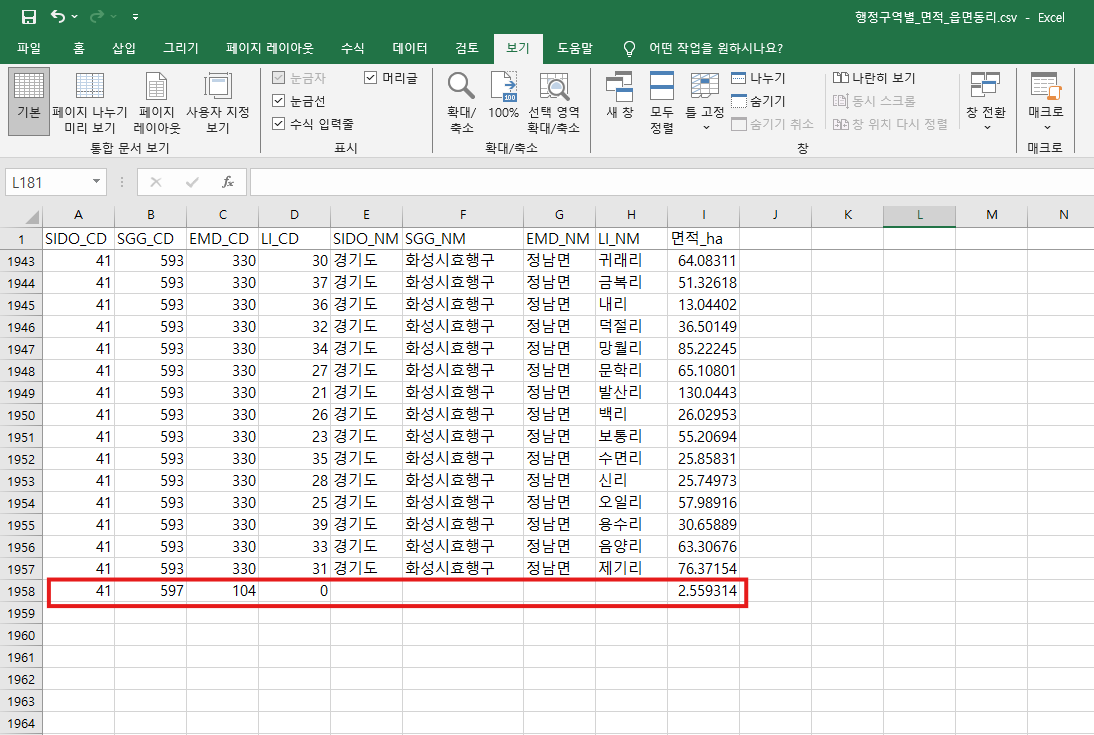

- 잘못된 데이터를 QGIS에서 확인해보니, '경기도 화성시동탄구 여울동'에 위치한 폴리곤이었다.(동코드 = 4159711500)
- 오산동 -> 여울동, 4159710400 -> 4159711500 으로 변경해야 한다.
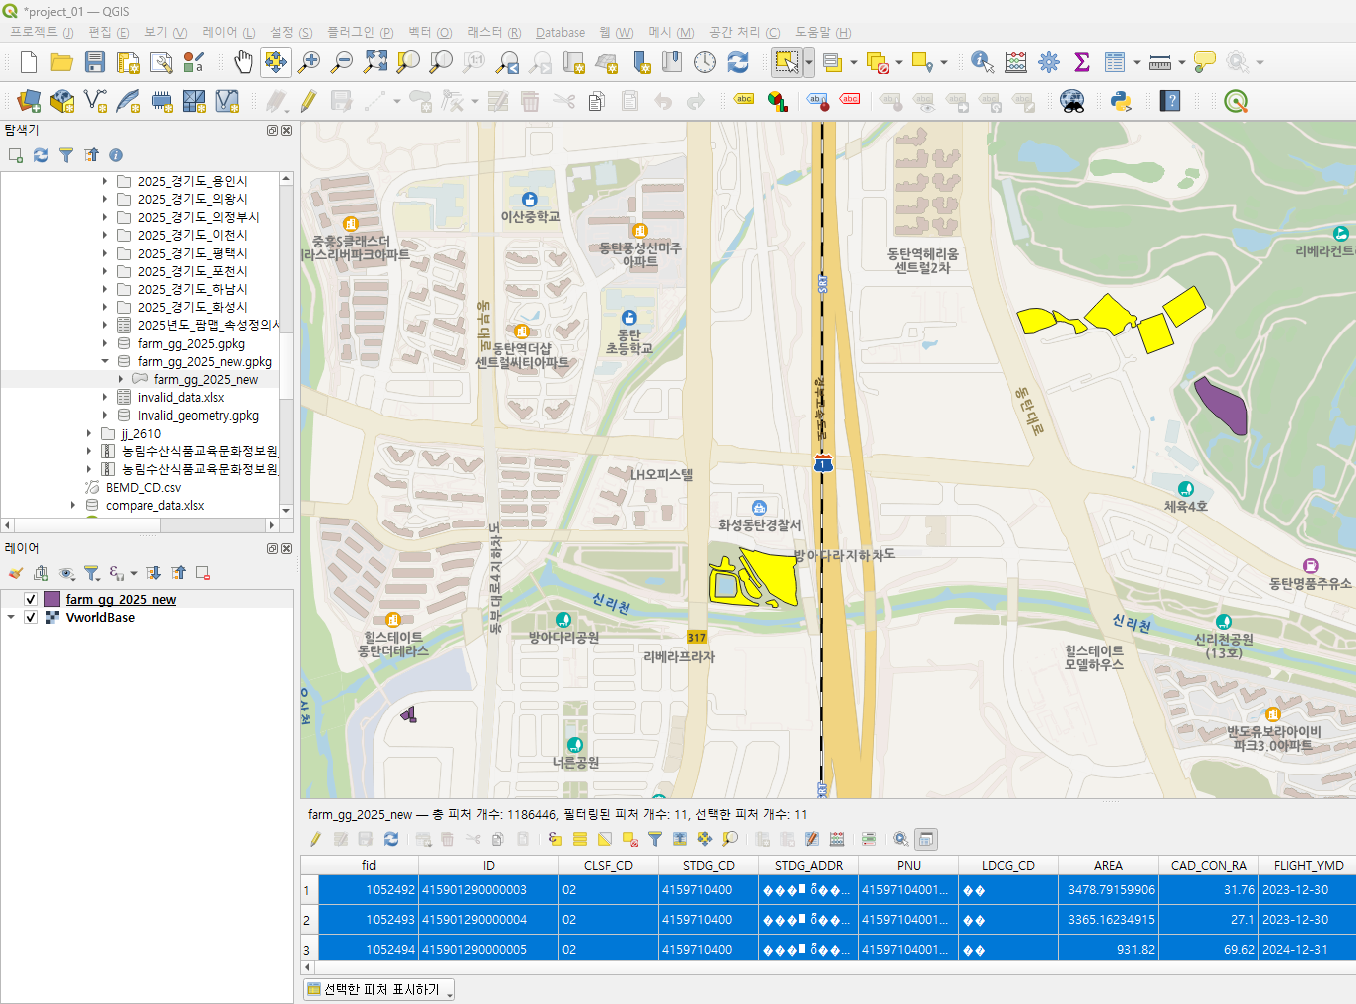

- 오류데이터를 검색했는데 잘못된 동코드 11건이 발견되었다.

In [98]:
farm_gg_2025_new[farm_gg_2025_new['STDG_CD'].astype(str).str.startswith('41597104')]

,ID,CLSF_CD,STDG_CD,STDG_ADDR,PNU,LDCG_CD,AREA,CAD_CON_RA,FLIGHT_YMD,UPDT_YMD,SIDO_CD,SGG_CD,EMD_CD,LI_CD,SIDO_NM,SGG_NM,EMD_NM,LI_NM,geometry
1052491,415901290000003,02,4159710400,경기도 화성시 동탄구 오산동,4159710400103400000,답,3478.791599,31.76,2023-12-30,2024-12-31,41,597,104,00,None,None,None,None,"POLYGON ((964750.539 1910120.133, 964810.513 1..."
1052492,415901290000004,02,4159710400,경기도 화성시 동탄구 오산동,4159710400103380000,답,3365.162349,27.10,2023-12-30,2024-12-31,41,597,104,00,None,None,None,None,"POLYGON ((964700.996 1910085, 964708.956 19100..."
1052493,415901290000005,02,4159710400,경기도 화성시 동탄구 오산동,4159710400103270000,전,931.820000,69.62,2024-12-31,2025-12-31,41,597,104,00,None,None,None,None,"POLYGON ((964556.807 1910091.299, 964554.538 1..."
1052494,415901290000006,02,4159710400,경기도 화성시 동탄구 오산동,4159710400103320001,전,4232.300000,43.28,2024-12-31,2025-12-31,41,597,104,00,None,None,None,None,"POLYGON ((964675 1910073.172, 964672.941 19100..."
1052495,415901290000007,02,4159710400,경기도 화성시 동탄구 오산동,4159710400109620048,답,6490.790000,25.86,2024-12-31,2025-12-31,41,597,104,00,None,None,None,None,"POLYGON ((964013.47 1909559.501, 963991.215 19..."
1052496,415971040000001,02,4159710400,경기도 화성시 동탄구 오산동,4159710400109620086,답,1037.850000,46.03,2024-12-31,2025-12-31,41,597,104,00,None,None,None,None,"POLYGON ((963965.088 1909563.173, 963962.339 1..."
1052497,415901290000009,02,4159710400,경기도 화성시 동탄구 오산동,4159710400109620085,답,2189.870000,27.51,2024-12-31,2025-12-31,41,597,104,00,None,None,None,None,"POLYGON ((963969.152 1909547.95, 963920.042 19..."
1052498,415901290000010,02,4159710400,경기도 화성시 동탄구 오산동,4159710400109620055,답,630.316812,38.94,2023-12-30,2024-12-31,41,597,104,00,None,None,None,None,"POLYGON ((963875.07 1909629.618, 963890.923 19..."
1057102,415971040000002,02,4159710400,경기도 화성시 동탄구 오산동,4159710400109620087,답,206.390000,77.76,2024-12-31,2025-12-31,41,597,104,00,None,None,None,None,"POLYGON ((963996.356 1909545.766, 963996.944 1..."
1057103,415971040000003,02,4159710400,경기도 화성시 동탄구 오산동,4159710400109620052,답,479.200000,82.27,2024-12-31,2025-12-31,41,597,104,00,None,None,None,None,"POLYGON ((963956.771 1909601.432, 963942.119 1..."


- 잘못된 데이터 수정

In [122]:
error = (farm_gg_2025_new['STDG_CD'].astype('string').eq('4159711500'))

farm_gg_2025_new.loc[error, 'SIDO_NM'] = '경기도'
farm_gg_2025_new.loc[error, 'SGG_NM'] = '화성시동탄구'
farm_gg_2025_new.loc[error, 'EMD_NM'] = '여울동'
farm_gg_2025_new.loc[error, 'EMD_CD'] = '115'
farm_gg_2025_new.loc[error, 'STDG_CD'] = '4159711500'
farm_gg_2025_new.loc[error, 'STDG_ADDR'] = '경기도 화성시동탄구 여울동'

- 수정 확인

In [120]:
farm_gg_2025_new[farm_gg_2025_new['STDG_CD'].astype(str).str.startswith('41597115')]

,ID,CLSF_CD,STDG_CD,STDG_ADDR,PNU,LDCG_CD,AREA,CAD_CON_RA,FLIGHT_YMD,UPDT_YMD,SIDO_CD,SGG_CD,EMD_CD,LI_CD,SIDO_NM,SGG_NM,EMD_NM,LI_NM,geometry
1052491,415901290000003,02,4159711500,경기도 화성시 동탄구 여울동,4159710400103400000,답,3478.791599,31.76,2023-12-30,2024-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((964750.539 1910120.133, 964810.513 1..."
1052492,415901290000004,02,4159711500,경기도 화성시 동탄구 여울동,4159710400103380000,답,3365.162349,27.10,2023-12-30,2024-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((964700.996 1910085, 964708.956 19100..."
1052493,415901290000005,02,4159711500,경기도 화성시 동탄구 여울동,4159710400103270000,전,931.820000,69.62,2024-12-31,2025-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((964556.807 1910091.299, 964554.538 1..."
1052494,415901290000006,02,4159711500,경기도 화성시 동탄구 여울동,4159710400103320001,전,4232.300000,43.28,2024-12-31,2025-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((964675 1910073.172, 964672.941 19100..."
1052495,415901290000007,02,4159711500,경기도 화성시 동탄구 여울동,4159710400109620048,답,6490.790000,25.86,2024-12-31,2025-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((964013.47 1909559.501, 963991.215 19..."
1052496,415971040000001,02,4159711500,경기도 화성시 동탄구 여울동,4159710400109620086,답,1037.850000,46.03,2024-12-31,2025-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((963965.088 1909563.173, 963962.339 1..."
1052497,415901290000009,02,4159711500,경기도 화성시 동탄구 여울동,4159710400109620085,답,2189.870000,27.51,2024-12-31,2025-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((963969.152 1909547.95, 963920.042 19..."
1052498,415901290000010,02,4159711500,경기도 화성시 동탄구 여울동,4159710400109620055,답,630.316812,38.94,2023-12-30,2024-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((963875.07 1909629.618, 963890.923 19..."
1057102,415971040000002,02,4159711500,경기도 화성시 동탄구 여울동,4159710400109620087,답,206.390000,77.76,2024-12-31,2025-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((963996.356 1909545.766, 963996.944 1..."
1057103,415971040000003,02,4159711500,경기도 화성시 동탄구 여울동,4159710400109620052,답,479.200000,82.27,2024-12-31,2025-12-31,41,597,115,00,경기도,화성시동탄구,여울동,None,"POLYGON ((963956.771 1909601.432, 963942.119 1..."


- 결과 재추출

In [ ]:
def area_calc(gdf):

    # 시도별 면적
    sido_area = (
        gdf
        .groupby(
            ['SIDO_CD', 'SIDO_NM'],
            dropna=False
        )
        .agg(면적_ha=('AREA', lambda x: x.sum() / 10_000))
        .reset_index()
    )

    # 시군구별 면적
    sgg_area = (
        gdf
        .groupby(
            ['SIDO_CD', 'SGG_CD', 'SIDO_NM', 'SGG_NM'],
            dropna=False
        )
        .agg(면적_ha=('AREA', lambda x: x.sum() / 10_000))
        .reset_index()
        .sort_values('SGG_NM', ascending=True)
    )

    # 읍면동리별 면적
    emdli_area = (
        gdf
        .groupby(
            [
                'SIDO_CD', 'SGG_CD', 'EMD_CD', 'LI_CD',
                'SIDO_NM', 'SGG_NM', 'EMD_NM', 'LI_NM'
            ],
            dropna=False
        )
        .agg(면적_ha=('AREA', lambda x: x.sum() / 10_000))
        .reset_index()
        .sort_values(['SGG_NM', 'EMD_NM', 'LI_NM'], ascending=True)
    )

    # CSV 저장
    sido_area.to_csv(
        '행정구역별면적_시도.csv',
        index=False,
        encoding='utf-8-sig'
    )

    sgg_area.to_csv(
        '행정구역별면적_시군구.csv',
        index=False,
        encoding='utf-8-sig'
    )

    emdli_area.to_csv(
        '행정구역별면적_읍면동리.csv',
        index=False,
        encoding='utf-8-sig'
    )

    display(sido_area.head())
    display(sgg_area.head())
    display(emdli_area.head())


area_calc(farm_gg_2025_new)

,SIDO_CD,SIDO_NM,면적_ha
0,41,경기도,156161.197564


,SIDO_CD,SGG_CD,SIDO_NM,SGG_NM,면적_ha
45,41,820,경기도,가평군,3126.520319
18,41,281,경기도,고양시덕양구,1941.417386
19,41,285,경기도,고양시일산동구,809.156212
20,41,287,경기도,고양시일산서구,1101.883213
21,41,290,경기도,과천시,194.321422


,SIDO_CD,SGG_CD,EMD_CD,LI_CD,SIDO_NM,SGG_NM,EMD_NM,LI_NM,면적_ha
1795,41,820,250,30,경기도,가평군,가평읍,개곡리,79.382143
1792,41,820,250,27,경기도,가평군,가평읍,경반리,54.785395
1799,41,820,250,34,경기도,가평군,가평읍,금대리,35.441446
1788,41,820,250,23,경기도,가평군,가평읍,달전리,35.013609
1787,41,820,250,22,경기도,가평군,가평읍,대곡리,24.842215
